# Bài 3 — Logistic Regression và Softmax Regression bằng Scikit-learn

Dùng cùng tập train/test MNIST và cách chia pixel cho 255 như Bài 1, Bài 2.

## 1. Đọc dữ liệu

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay

ROOT = Path.cwd()
if (ROOT / 'Lab2_du_lieu_MNIST').is_dir():
    ROOT = ROOT / 'Lab2_du_lieu_MNIST'

data = np.load(ROOT / 'data' / 'mnist.npz')
X_train = data['X_train'].astype(np.float32) / 255.0
X_test = data['X_test'].astype(np.float32) / 255.0
y_train = data['y_train']
y_test = data['y_test']

train_mask = (y_train == 0) | (y_train == 1)
test_mask = (y_test == 0) | (y_test == 1)
X_train_binary = X_train[train_mask]
X_test_binary = X_test[test_mask]
y_train_binary = y_train[train_mask]
y_test_binary = y_test[test_mask]

output = ROOT / 'results' / 'bai3_scikit_learn'
output.mkdir(parents=True, exist_ok=True)

## 2. Logistic Regression

In [2]:
logistic_model = LogisticRegression(C=1.0, solver='lbfgs', max_iter=1000, tol=1e-4)
logistic_model.fit(X_train_binary, y_train_binary)
binary_pred = logistic_model.predict(X_test_binary)
binary_report = classification_report(y_test_binary, binary_pred, output_dict=True, zero_division=0)
binary_cm = confusion_matrix(y_test_binary, binary_pred)
print(classification_report(y_test_binary, binary_pred, digits=4, zero_division=0))

              precision    recall  f1-score   support

           0     1.0000    0.9990    0.9995       980
           1     0.9991    1.0000    0.9996      1135

    accuracy                         0.9995      2115
   macro avg     0.9996    0.9995    0.9995      2115
weighted avg     0.9995    0.9995    0.9995      2115



## 3. Softmax Regression

In [3]:
softmax_model = LogisticRegression(C=1.0, solver='lbfgs', max_iter=1000, tol=1e-4)
softmax_model.fit(X_train, y_train)
multi_pred = softmax_model.predict(X_test)
multi_report = classification_report(y_test, multi_pred, output_dict=True, zero_division=0)
multi_cm = confusion_matrix(y_test, multi_pred)
print(classification_report(y_test, multi_pred, digits=4, zero_division=0))

              precision    recall  f1-score   support

           0     0.9532    0.9765    0.9647       980
           1     0.9628    0.9797    0.9712      1135
           2     0.9281    0.9012    0.9145      1032
           3     0.9049    0.9139    0.9094      1010
           4     0.9380    0.9399    0.9390       982
           5     0.8963    0.8722    0.8841       892
           6     0.9441    0.9520    0.9480       958
           7     0.9349    0.9222    0.9285      1028
           8     0.8847    0.8819    0.8833       974
           9     0.9114    0.9177    0.9146      1009

    accuracy                         0.9268     10000
   macro avg     0.9258    0.9257    0.9257     10000
weighted avg     0.9266    0.9268    0.9266     10000



## 4. Ma trận nhầm lẫn

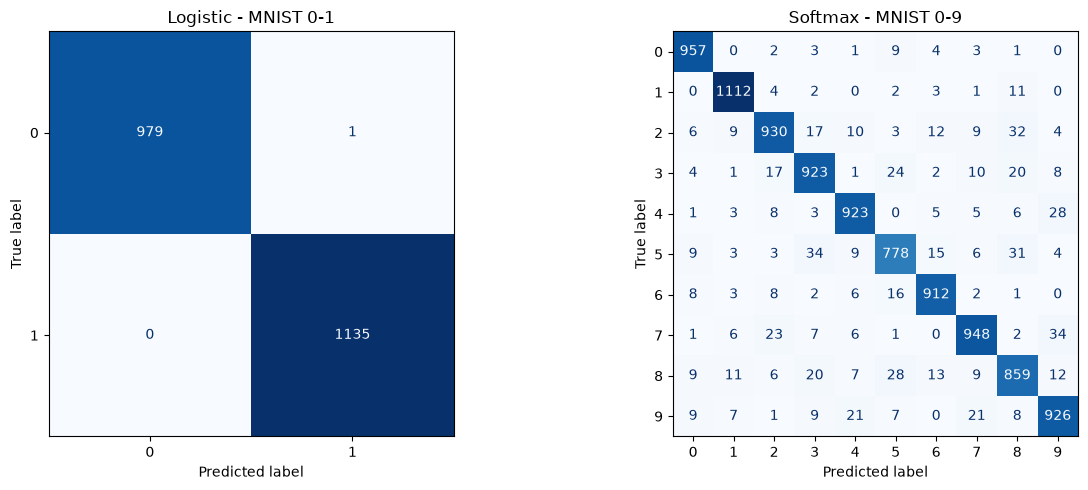

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(binary_cm).plot(ax=axes[0], colorbar=False, cmap='Blues')
ConfusionMatrixDisplay(multi_cm).plot(ax=axes[1], colorbar=False, cmap='Blues')
axes[0].set_title('Logistic - MNIST 0-1')
axes[1].set_title('Softmax - MNIST 0-9')
plt.tight_layout()
plt.savefig(output / 'confusion_matrices.png', dpi=160)
plt.show()

## 5. Bảng kết quả

In [5]:
result1 = json.loads((ROOT / 'results' / 'bai1_logistic_numpy' / 'metrics.json').read_text(encoding='utf-8'))
result2 = json.loads((ROOT / 'results' / 'bai2_softmax_numpy' / 'metrics.json').read_text(encoding='utf-8'))
comparison = pd.DataFrame([
    ['Logistic - NumPy', result1['accuracy'], result1['macro_precision'], result1['macro_recall'], result1['macro_f1']],
    ['Logistic - Scikit-learn', accuracy_score(y_test_binary, binary_pred), binary_report['macro avg']['precision'],
     binary_report['macro avg']['recall'], binary_report['macro avg']['f1-score']],
    ['Softmax - NumPy', result2['accuracy'], result2['macro_precision'], result2['macro_recall'], result2['macro_f1']],
    ['Softmax - Scikit-learn', accuracy_score(y_test, multi_pred), multi_report['macro avg']['precision'],
     multi_report['macro avg']['recall'], multi_report['macro avg']['f1-score']]
], columns=['name', 'accuracy', 'macro_precision', 'macro_recall', 'macro_f1'])
print(comparison.round(4).to_string(index=False))
comparison.to_csv(output / 'comparison.csv', index=False, encoding='utf-8-sig')

                   name  accuracy  macro_precision  macro_recall  macro_f1
       Logistic - NumPy    0.9991           0.9991        0.9990    0.9990
Logistic - Scikit-learn    0.9995           0.9996        0.9995    0.9995
        Softmax - NumPy    0.9011           0.9001        0.8997    0.8996
 Softmax - Scikit-learn    0.9268           0.9258        0.9257    0.9257


## 6. Lưu kết quả

In [6]:
metrics = {'sklearn_version': sklearn.__version__,
           'configuration': {'C': 1.0, 'solver': 'lbfgs', 'max_iter': 1000, 'tol': 1e-4},
           'logistic': {'classification_report': binary_report, 'confusion_matrix': binary_cm.tolist(),
                        'n_iter': logistic_model.n_iter_.tolist()},
           'softmax': {'classification_report': multi_report, 'confusion_matrix': multi_cm.tolist(),
                       'n_iter': softmax_model.n_iter_.tolist()}}
(output / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
with (output / 'classification_reports.txt').open('w', encoding='utf-8') as f:
    print('Logistic Regression - MNIST 0-1', file=f)
    print(classification_report(y_test_binary, binary_pred, digits=4, zero_division=0), file=f)
    print('Softmax Regression - MNIST 0-9', file=f)
    print(classification_report(y_test, multi_pred, digits=4, zero_division=0), file=f)
np.savetxt(output / 'logistic_test_predictions.csv', np.column_stack([y_test_binary, binary_pred]),
           delimiter=',', header='true_label,predicted_label', comments='', fmt='%d')
np.savetxt(output / 'softmax_test_predictions.csv', np.column_stack([y_test, multi_pred]),
           delimiter=',', header='true_label,predicted_label', comments='', fmt='%d')
model_paths = joblib.dump({'logistic': logistic_model, 'softmax': softmax_model,
             'pixel_divisor': 255.0, 'sklearn_version': sklearn.__version__}, output / 'models.joblib')